<a href="https://colab.research.google.com/github/TejasShrestha/Data-201-Project-1/blob/main/Project_1_DATA_201.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project 1 DATA-201**

In [2]:
#mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
# importing the bank marketing dataset
file_path = "/content/drive/MyDrive/EC/DATA-201/Datasets/bank-full.csv"

# Seperating the dataset into columns as the dataset was seperated by semi-colons prior
bank = pd.read_csv(file_path, sep=';')

bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## **Part 1: Understand Your Problem**

**1.** Each row of my dataset represents one client's phone call in a marketing campaign created by a Portuguese Bank. The response variable is whether the client subscribed and the two classes are yes they subscribed and no they did not subscribe.

**2.** The predictors I believe could be useful for classification are "poutcome" (person's outcome from a previous marketing campaign), "balance" (average yearly balance), "housing" (does the person have housing loan?), loan (does the person have a personal loan?), and contact (how the person was contacted). I believe all these predictors can be useful to evaluate why a person declined or accepted the subscription offers.

**3.** Around 39,922 are in class "no" and 5,289 are in class "yes". Using this information, the dataset is imbalanced as there is far more people who did not purchase the subscription than those who did purchase it.

**4.** Using "yes" the person subscribed as the positive class. False positive is when the model predicts the client will subscribe but they don't. The bank wastes their time calling someone who was not going to buy. False negative is when the model predicts the client won't subscribe when in reality they would have.

**5.** In my opinion, false negatives are more concerning as those are the people that would have actually supported the subscription, gaining more subscriptions overall. This is a tougher loss in my opinion especially looking at the overwhelming counts of people that declined compared to the people that subscribed.

In [4]:
# 3. Examining the Distribution of y
bank["y"].value_counts()

,count
y,
no,39922
yes,5289


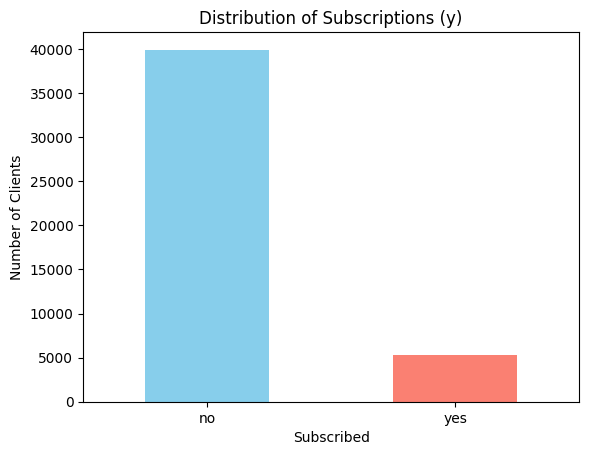

In [5]:
# 3. Examining the Distribution of y Visually
import matplotlib.pyplot as plt
bank['y'].value_counts().plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Distribution of Subscriptions (y)')
plt.xlabel('Subscribed')
plt.ylabel('Number of Clients')
plt.xticks(rotation=0)
plt.show()

We can see that there are way more people who responded no to the subscription than the amount of people that accepted the subscription.

## **Part 2: Explore and Prepare the Data**

**1. Investigate your features and predictors**

In [6]:
#Shape of the Bank dataset
print(bank.shape)

(45211, 17)


In [7]:
#Investigating The Dataset

# Examining the types of variables
print(bank.dtypes)

# Counting each category in workclass
print(bank.value_counts())

age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object
age  job      marital  education  default  balance  housing  loan  contact    day  month  duration  campaign  pdays  previous  poutcome  y  
95   retired  married  secondary  no       0        no       no    telephone  1    oct    215       1         -1     0         unknown   no     1
18   student  single   primary    no       608      no       no    cellular   12   aug    267       1         -1     0         unknown   yes    1
                                                                              13   nov    210       1          93    1         success   yes    1
                                           1944     no       no    

Observing the value counts for each of my selected categorical predictors as well as using the describe function for my only numerical predictor.

In [8]:
bank["poutcome"].value_counts()

,count
poutcome,
unknown,36959
failure,4901
other,1840
success,1511


There are lots of Unknown value counts in poutcome compared to the other counts.

In [9]:
bank["contact"].value_counts()

,count
contact,
cellular,29285
unknown,13020
telephone,2906


Majority of people were contacted through celluar but the Unknown counts take up a large majority as well.

In [10]:
bank["housing"].value_counts()

,count
housing,
yes,25130
no,20081


The value counts on whether or not a person has a housing loan or not were much closer than the other predictors.

In [11]:
bank["loan"].value_counts()

,count
loan,
no,37967
yes,7244


A large majority of people do not have a personal loan compared to the people that do.

In [12]:
#Balance is my only numerical variable
bank['balance'].describe()

,balance
count,45211.000000
mean,1362.272058
std,3044.765829
min,-8019.000000
25%,72.000000
50%,448.000000
75%,1428.000000
max,102127.000000


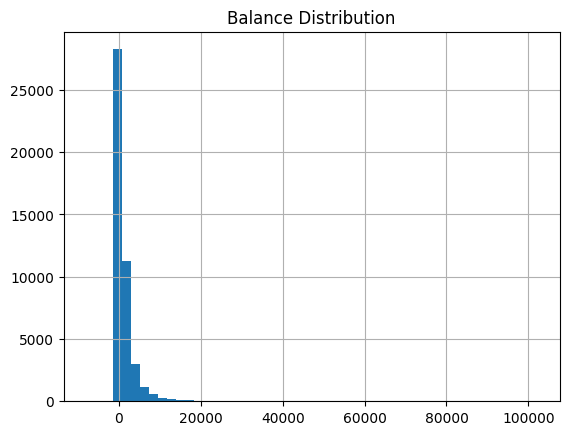

In [13]:
# Histogram distribution of the balance predictor

import matplotlib.pyplot as plt
bank["balance"].hist(bins=50); plt.title("Balance Distribution"); plt.show()

We can see that the distribution of the balance variable is heavilly right-skewed with some outliers in the negative numbers and towards the 100000 count with the min being -8019 and max being 102127.

**2. Determine whether your dataset contains missing values. If it does, explain how you handled them.**

Using the data from https://archive.ics.uci.edu/dataset/222/bank%2Bmarketing?wtime=%7Bseek_to_second_number%7D&, there are missing values under the variables "contact," "pdays," & "poutcome." I will only be handling the "contact" & "poutcome" na values because those are the only variables from the na's that I will be focusing on.

In [14]:
bank['contact'].value_counts()

,count
contact,
cellular,29285
unknown,13020
telephone,2906


For "contact", since the unknown contact has over 13000 counts which is a large portion of the dataset, I will keep all the unknown values as removing them could deminish valuable information required for the later parts.

In [15]:
bank['poutcome'].value_counts()

,count
poutcome,
unknown,36959
failure,4901
other,1840
success,1511


For "poutcome", since the unknown contact has over 36000 counts which is majority of the dataset, I will keep all the unknown values as removing them could deminish valuable information required for the later parts.

**3. Determine whether any categorical predictors need to be encoded before modeling.**

The categorical predictors that need to encoded before modeling that I chose are "housing", "loan", "contact", "poutcome", and the target variable "y".

In [16]:
#Converting all variables into numeric form
bank["housing_num"] = bank["housing"].map({
    "no": 0,
    "yes": 1
})
bank["loan_num"] = bank["loan"].map({
    "no": 0,
    "yes": 1
})
bank["y_num"] = bank["y"].map({
    "no": 0,
    "yes": 1
})
bank["contact_num"] = bank["contact"].map({
    "cellular": 0,
    "unknown":1,
    "telephone": 2
})
bank["poutcome_num"] = bank["poutcome"].map({
    "unknown": 0,
    "failure":1,
    "other": 2,
    "success":3
})
bank

,age,job,marital,education,default,balance,housing,loan,contact,day,...,campaign,pdays,previous,poutcome,y,housing_num,loan_num,y_num,contact_num,poutcome_num
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,...,1,-1,0,unknown,no,1,0,0,1,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,...,1,-1,0,unknown,no,1,0,0,1,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,...,1,-1,0,unknown,no,1,1,0,1,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,...,1,-1,0,unknown,no,1,0,0,1,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,...,1,-1,0,unknown,no,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,...,3,-1,0,unknown,yes,0,0,1,0,0
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,...,2,-1,0,unknown,yes,0,0,1,0,0
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,...,5,184,3,success,yes,0,0,1,0,3
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,...,4,-1,0,unknown,no,0,0,0,2,0


**4. Divide the data, then use k-fold CV on training data.**

In [17]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold
)
# Separate predictors and target
X = bank[["contact_num", "housing_num", "balance","loan_num","poutcome_num"]]
y = bank["y_num"]

categorical_features = ["contact_num", "housing_num", "loan_num","poutcome_num"]

# Build preprocessing step
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

def pipeline(my_model):
  # Combine preprocessing with logistic regression
  pipe = make_pipeline(
      preprocess,
      my_model)
  return pipe

# Split into training and testing & stratify
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=0)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=4
)

def cross_validation(my_model):
# KNN without scaling
  raw_cv = cross_val_score(
      pipeline(my_model),
      X_train,
      y_train,
      cv=cv,
      scoring="accuracy"
  )
  return raw_cv.mean()

We only have one numeric variable so we do not need to standardize any of my classfiers in this case.

## **Part 3: Build Your Classifiers**

**Logistic Regression**

In [18]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     KFold, StratifiedKFold, LeaveOneOut, GridSearchCV)

# For Logistic Regression:

print("CV Accuracy Score = ",cross_validation(LogisticRegression(max_iter=5000)))
logr = pipeline(LogisticRegression(max_iter=5000))
#Fit the final model using all training data
logr.fit(X_train, y_train)

#Get predicted probabilities on the unseen test set
logr.classes_

#get the probability of defaulting "Yes"
pred_yes = logr.predict(X_test)
prob_yes = logr.predict_proba(X_test)[:, 1]

print("Probability = ",prob_yes[:10])
print("Prediction = ",pred_yes[:10])

CV Accuracy Score =  0.8930931878936808
Probability =  [0.03419484 0.11122354 0.09060201 0.09060201 0.15053341 0.09060201
 0.16074436 0.09060201 0.11122354 0.09682749]
Prediction =  [0 0 0 0 0 0 0 0 0 0]


**Linear Discriminant Analysis (LDA)**

In [19]:
# For LDA:

print("CV Accuracy Score = ",cross_validation(LinearDiscriminantAnalysis()))
LDA = pipeline(LinearDiscriminantAnalysis())
#Fit the final model using all training data
LDA.fit(X_train, y_train)

#Get predicted probabilities on the unseen test set
LDA.classes_

#get the probability of defaulting "Yes"
pred_yes_LDA = LDA.predict(X_test)
prob_yes_LDA = LDA.predict_proba(X_test)[:, 1]

print("Probability = ",prob_yes_LDA[:10])
print("Prediction = ",pred_yes_LDA[:10])

CV Accuracy Score =  0.892768786760899
Probability =  [0.02951781 0.07336218 0.05898845 0.05898845 0.11309943 0.05898845
 0.10901198 0.05898845 0.07336218 0.06980398]
Prediction =  [0 0 0 0 0 0 0 0 0 0]


**Quadratic Discriminant Analysis (QDA)**

In [20]:
# For QDA:

print("CV Accuracy Score = ",cross_validation(QuadraticDiscriminantAnalysis()))
QDA = pipeline(QuadraticDiscriminantAnalysis())
#Fit the final model using all training data
QDA.fit(X_train, y_train)

#Get predicted probabilities on the unseen test set
QDA.classes_

#get the probability of defaulting "Yes"
pred_yes_QDA = QDA.predict(X_test)
prob_yes_QDA = QDA.predict_proba(X_test)[:, 1]

print("Probability = ",prob_yes_QDA[:10])
print("Prediction = ",pred_yes_QDA[:10])

/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

CV Accuracy Score =  0.7756335974573951
Probability =  [8.35203377e-05 2.45963080e-03 4.90539690e-03 4.90539690e-03
 9.97808980e-01 4.90539690e-03 1.34806967e-01 4.90539690e-03
 2.45963080e-03 1.40354996e-04]
Prediction =  [0 0 0 0 1 0 0 0 0 0]


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(


**K-Nearest Neighbor (KNN)**

In [21]:
# Create the pipeline
KNN = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

# Define the hyperparameter grid
KNN_grid = {
    'kneighborsclassifier__n_neighbors': [1, 21, 51, 61, 101],
    'kneighborsclassifier__weights': ['uniform', 'distance']
}

# Set up GridSearchCV
grid_KNN = GridSearchCV(
    KNN,
    KNN_grid,
    cv=5,
    scoring='roc_auc'
)

# Fit on training data
grid_KNN.fit(X_train, y_train)

# Corrected attributes: best_params_ and best_score_
print("KNN best parameters:", grid_KNN.best_params_)
print("KNN best CV ROC and AUC:", round(grid_KNN.best_score_, 4))

KNN best parameters: {'kneighborsclassifier__n_neighbors': 101, 'kneighborsclassifier__weights': 'uniform'}
KNN best CV ROC and AUC: 0.7189


As I increased range of KNN, the highest number became the new best parameter leading to the best CV ROC and AUC value to keep increasing infinitely, so I will stop at K being 101 for the sake of this project.

## **Part 4: Evaluate Your Models**

Logistic Regression Evaluation

In [22]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

#Threshold = 50%
pred_50 = np.where(
    prob_yes >= 0.50,
    1,  # 1 represents 'Yes'
    0   # 0 represents 'No'
)

#Confusion Matrix - use [0, 1] instead of ['No', 'Yes'] because y_test contains 0 and 1
cm = confusion_matrix(
    y_test,
    pred_50,
    labels=[0, 1]
)

print("Logistic Regression Confusion Matrix:")
print(cm)

TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)
#Metrics

accuracy = accuracy_score(
    y_test,
    pred_50
)

# Changed pos_label from 'Yes' to 1 since the labels are numeric [0, 1]
precision = precision_score(
    y_test,
    pred_50,
    pos_label=1
)

recall = recall_score(
    y_test,
    pred_50,
    pos_label=1
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test,
    pred_50,
    pos_label=1
)

#AUC
auc = roc_auc_score(
    y_test,
    prob_yes
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)
print("ROC-AUC:", auc)

Logistic Regression Confusion Matrix:
[[9858  123]
 [1085  237]]
TN: 9858
FP: 123
FN: 1085
TP: 237
Accuracy: 0.8931257188357073
Precision: 0.6583333333333333
Recall: 0.17927382753403934
Specificity: 0.9876765855124737
F1: 0.28180737217598095
ROC-AUC: 0.7240120828666752


LDA Evaluation

In [23]:
#Threshold = 50%
pred_50 = np.where(
    prob_yes_LDA >= 0.50,
    1,  # 1 represents 'Yes'
    0   # 0 represents 'No'
)

#Confusion Matrix - use [0, 1] instead of ['No', 'Yes'] because y_test contains 0 and 1
cm = confusion_matrix(
    y_test,
    pred_50,
    labels=[0, 1]
)

print("LDA Confusion Matrix:")
print(cm)

TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

#Metrics

accuracy = accuracy_score(
    y_test,
    pred_50
)

# Changed pos_label from 'Yes' to 1 since the labels are numeric [0, 1]
precision = precision_score(
    y_test,
    pred_50,
    pos_label=1
)

recall = recall_score(
    y_test,
    pred_50,
    pos_label=1
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test,
    pred_50,
    pos_label=1
)

#AUC
auc = roc_auc_score(
    y_test,
    prob_yes
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)
print("ROC-AUC:", auc)

LDA Confusion Matrix:
[[9852  129]
 [1079  243]]
TN: 9852
FP: 129
FN: 1079
TP: 243
Accuracy: 0.8931257188357073
Precision: 0.6532258064516129
Recall: 0.1838124054462935
Specificity: 0.9870754433423504
F1: 0.28689492325855964
ROC-AUC: 0.7240120828666752


QDA Evaluation

In [24]:
#Threshold = 50%
pred_50 = np.where(
    prob_yes_QDA >= 0.50,
    1,  # 1 represents 'Yes'
    0   # 0 represents 'No'
)

#Confusion Matrix - use [0, 1] instead of ['No', 'Yes'] because y_test contains 0 and 1
cm = confusion_matrix(
    y_test,
    pred_50,
    labels=[0, 1]
)

print("QDA Confusion Matrix:")
print(cm)

TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

#Metrics

accuracy = accuracy_score(
    y_test,
    pred_50
)

# Changed pos_label from 'Yes' to 1 since the labels are numeric [0, 1]
precision = precision_score(
    y_test,
    pred_50,
    pos_label=1
)

recall = recall_score(
    y_test,
    pred_50,
    pos_label=1
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test,
    pred_50,
    pos_label=1
)

#AUC
auc = roc_auc_score(
    y_test,
    prob_yes_QDA
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)
print("ROC-AUC:", auc)

QDA Confusion Matrix:
[[9456  525]
 [1008  314]]
TN: 9456
FP: 525
FN: 1008
TP: 314
Accuracy: 0.8643722905423339
Precision: 0.3742550655542312
Recall: 0.23751891074130105
Specificity: 0.947400060114217
F1: 0.2906062008329477
ROC-AUC: 0.6988293642944287


KNN Evaluation

In [25]:
# Extract the best estimator and get predicted probabilities for KNN
best_KNN = grid_KNN.best_estimator_
prob_yes_KNN = best_KNN.predict_proba(X_test)[:, 1]

#Threshold = 50%
pred_50 = np.where(
    prob_yes_KNN >= 0.50,
    1,  # 1 represents 'Yes'
    0   # 0 represents 'No'
)

#Confusion Matrix - use [0, 1] instead of ['No', 'Yes'] because y_test contains 0 and 1
cm = confusion_matrix(
    y_test,
    pred_50,
    labels=[0, 1]
)

print("KNN Confusion Matrix:")
print(cm)

TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)

#Metrics

accuracy = accuracy_score(
    y_test,
    pred_50
)

# Changed pos_label from 'Yes' to 1 since the labels are numeric [0, 1]
precision = precision_score(
    y_test,
    pred_50,
    pos_label=1
)

recall = recall_score(
    y_test,
    pred_50,
    pos_label=1
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test,
    pred_50,
    pos_label=1
)

#AUC
auc = roc_auc_score(
    y_test,
    prob_yes_KNN
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)
print("ROC-AUC:", auc)

KNN Confusion Matrix:
[[9864  117]
 [1094  228]]
TN: 9864
FP: 117
FN: 1094
TP: 228
Accuracy: 0.8928603025745377
Precision: 0.6608695652173913
Recall: 0.17246596066565809
Specificity: 0.9882777276825969
F1: 0.2735452909418116
ROC-AUC: 0.7272418199723196


## **Part 5: Reflect**

Logistic Regression:
*   Accuracy: 89.3%
*   Precision: 65.8%
* Recall: 17.9%
* Specificity: 98.8%
* F1: 0.282
* ROC-AUC: 0.72

LDA:
*   Accuracy: 89.3%
*   Precision: 65.3%
* Recall: 18.4%
* Specificity: 98.7%
* F1: 0.287
* ROC-AUC: 0.72

QDA:
*   Accuracy: 86.4%
*   Precision: 37.4%
* Recall: 23.8%
* Specificity: 94.7%
* F1: 0.291
* ROC-AUC: 0.70

KNN (k = 101):
*   Accuracy: 89.3%
*   Precision: 66.1%
* Recall: 17.2%
* Specificity: 98.8%
* F1: 0.274
* ROC-AUC: 0.73

In Part 1, I stated that False Negatives are the most concerning in my opinion because a False Negative means that the model predicts that a client won't subscribe when they actually would have, causing the bank to miss out on an oppurtunity to gain a subscription. Because the dataset is highly imbalanced with over 88% responding "No", "Accuracy" is not useful in this case. Due to this, the other scores we obtained are more important.

Currently, all models have very bad Recall percentages, not even peaking over 25%. This means that the models are missing about 3/4 of potential subscribers at the 50% threshold leading to higher False Negative counts.

The F1-score is the mean of Precision and Recall and it makes sure we don't waste too many phone calls on clients not interested about the subscription. Since the F1-scores are very low, this tells us that the balance of our classifier is weak due to Recall.

Since the 50% threshold is bringing in very low Recall, ROC-AUC is highly informative. It tells us how well the models rank the probabilities of subscribers vs. non-subscribers, regardless of the threshold. Since the ROC-AUC scores are pretty strong, we know that the models are good at ranking. If we lower the threshold the bank can improve the recall number

## **Part 6: ROC and AUC**

Logistic Regression ROC Curve

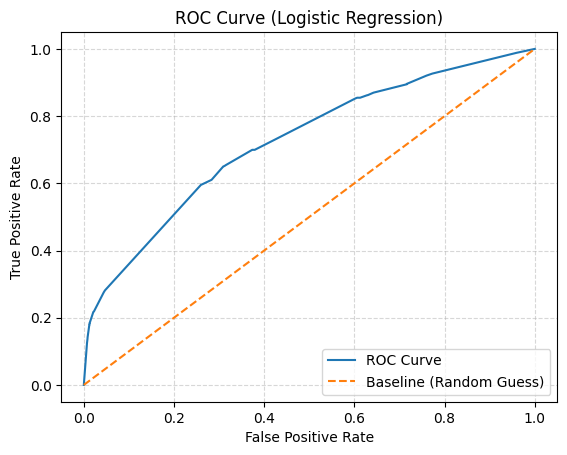

In [27]:
import matplotlib.pyplot as plt

# y_test is already 0/1 integers from bank["y_num"], so we do not need to convert it again!
# Converting it again was turning all values to 0.

# calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    prob_yes
)

# plot
plt.plot(
    fpr,
    tpr,
    label="ROC Curve"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Baseline (Random Guess)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Logistic Regression)")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

LDA ROC Curve

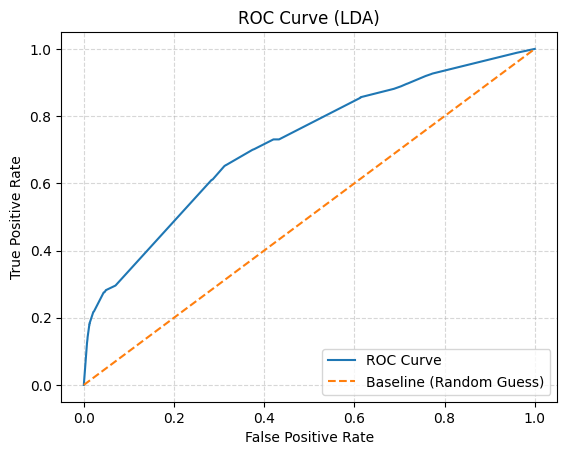

In [28]:
# y_test is already 0/1 integers from bank["y_num"], so we do not need to convert it again!
# Converting it again was turning all values to 0.

# calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    prob_yes_LDA
)

# plot
plt.plot(
    fpr,
    tpr,
    label="ROC Curve"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Baseline (Random Guess)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (LDA)")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

QDA ROC Curve

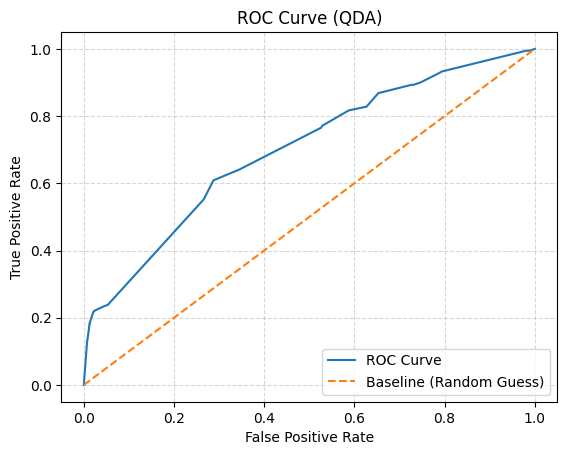

In [29]:
# y_test is already 0/1 integers from bank["y_num"], so we do not need to convert it again!
# Converting it again was turning all values to 0.

# calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    prob_yes_QDA
)

# plot
plt.plot(
    fpr,
    tpr,
    label="ROC Curve"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Baseline (Random Guess)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (QDA)")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

KNN ROC Curve

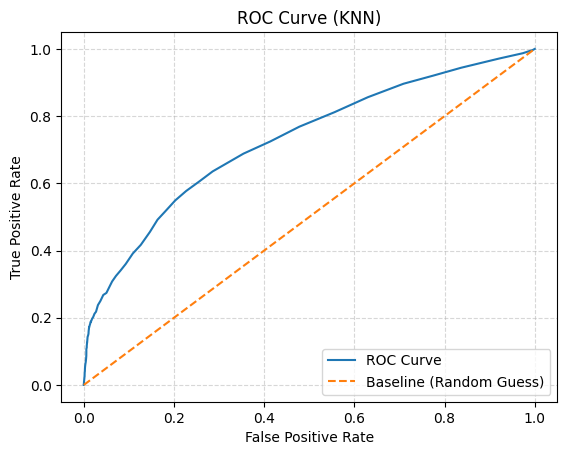

In [30]:
# y_test is already 0/1 integers from bank["y_num"], so we do not need to convert it again!
# Converting it again was turning all values to 0.

# calculate the curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    prob_yes_KNN
)

# plot
plt.plot(
    fpr,
    tpr,
    label="ROC Curve"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Baseline (Random Guess)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (KNN)")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

#### **Reporting the ROC-AUC Scores Obtained from Part 4**

*   **KNN (k = 101):** 0.7272
*   **Logistic Regression:** 0.7240
*   **LDA:** 0.7185
*   **QDA:** 0.6988

ROC-AUC calculates the ability of the model to tell the difference between clients who will subscribe compared to those who won't. If we randomly pick one client who actually subscribed and one client who declined, the ROC-AUC is the probability that our model will assign a higher subscription probability to the actual subscriber than to the non-subscriber.

 * An AUC of 0.5 represents the random guess threshold and if it is 0.5, the model can not really predict subscribers from non-subscribers.
 * An AUC of 1.0 corresponds to the model correctly seperating every single subscriber from non-subscribers perfectly.
  * My best model is KNN and it has an AUC of 0.723. This tells us that there is a 72.3% chance that the model will correctly rank a true subscriber higher than a non-subscriber.

Since my ROC-AUC scores are fairly strong at 0.72, it proves the models are good at ranking high-potential clients at the top.

## **Part 7: Final Analysis**

#### **1. Compare the performance of your four classifiers. What are the most important differences?**
Across all four classifiers evaluated at the default 50% threshold, I observed a pattern:
*   Accuracy was very high for Logistic Regression, LDA, and KNN with all sitting around the high 80%, with QDA having a slightly lower accuracy at 86.4%.
*   Precision was decent on KNN, Logistic Regression, and LDA with all sitting around the mid 60s in percent. This tells us that when they predict a client will subscribe, they are correct nearly 66% of the time. QDA far worse at predicting whether a cleint will subscribe as it has a precision percentage of 37.4\%.
*   Recall is very low for all models, with KNN, Logistic Regression, and LDA failing to identify over a majority of subscribers with a Recall range between 17.2% to 18.4%. QDA performs slightly better at 23.8%, but is still very weak.
*   ROC-AUC is by far the most useful. KNN had the best model in this category sitting at at 0.7272, followed closely by the other models only have a range being seperated by around 0.03 for all four models.

#### **2. Identify the model you would deploy for this specific application and justify the choice using your results and the consequences of classification errors.**
I would deploy the Logistic Regression model. All four models scored very
closely on the ROC-AUC, so it would make sense to just go with the simpler Logistic Regression model. Recall is the most important statistic to remove false negatives in this case, so I lowered the threshold from 50% to 15% for the Logistic regression model and got the new values above that reduces the number of False Negatives and improves the Recall percentage from 17.9% to
61%. I would rather spend more time trying to convince other customers to subscribe rather than lose out on interested customers. Logistic Regression delivers a high ROC-AUC of 0.724, showing it can successfully rank high-potential subscribers above non-subscribers. I ran the lowered threshold in the code chunk below.

#### **3. Explain one limitation of your analysis**
One limitation of my analysis is how the dataset highly imbalanced. Since 88.3% of the dataset represents "No" responses, the classifiers naturally resort to predicting "No". Another limitation is the amount of "Unknowns" throughout several of the predictors. With "poutcome" and "contact" being two very important predictors that I utilized in seeing the relationship between non-subscribers and subscribers, it does not help that there were almost 37,000 in the unknown category in "poutcome" and over 13,000 in the unknown category in "contact". It would help if we could actually figure out how these people were either contacted and how they responded in a previous campaign. More predictors such as the detailed demographics could also have help improved my analysis.

#### **4. What additional information or data would you want before using this model in the real world?**

Like I said in the previous question, I believe it would be useful to have the real-data in how the "unknown" people were contacted and how they responded to a prior campaign. This is valuable information that would have shifted my analysis drastically if known. I would also want more information about each person contacted such as their gender, race, yearly income, etc. This is all valuable information that may be a key tool in determining why they responded the way they did to the subscription.


**Logistic Regression At a Lowered Threshold (15% Threshold)**

In [31]:
#Threshold = 15%
pred_15 = np.where(
    prob_yes >= 0.15,
    1,  # 1 represents 'Yes'
    0   # 0 represents 'No'
)

#Confusion Matrix - use [0, 1] instead of ['No', 'Yes'] because y_test contains 0 and 1
cm = confusion_matrix(
    y_test,
    pred_15,
    labels=[0, 1]
)

print("Logistic Regression Confusion Matrix (at 15% threshold):")
print(cm)

TN, FP, FN, TP = cm.ravel()

print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TP:", TP)
#Metrics

accuracy = accuracy_score(
    y_test,
    pred_15
)

# Changed pos_label from 'Yes' to 1 since the labels are numeric [0, 1]
precision = precision_score(
    y_test,
    pred_15,
    pos_label=1
)

recall = recall_score(
    y_test,
    pred_15,
    pos_label=1
)

specificity = TN / (TN + FP)

f1 = f1_score(
    y_test,
    pred_15,
    pos_label=1
)

#AUC
auc = roc_auc_score(
    y_test,
    prob_yes
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1:", f1)
print("ROC-AUC:", auc)

Logistic Regression Confusion Matrix (at 15% threshold):
[[7153 2828]
 [ 515  807]]
TN: 7153
FP: 2828
FN: 515
TP: 807
Accuracy: 0.704237812970008
Precision: 0.2220082530949106
Recall: 0.6104387291981845
Specificity: 0.7166616571485823
F1: 0.32560016138793624
ROC-AUC: 0.7240120828666752


Logistic Regression (15% Threshold):
*   Accuracy: 70.4%
*   Precision: 22.2%
* Recall: 61.0%
* Specificity: 71.7%
* F1: 0.326
* ROC-AUC: 0.72